Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


In [1]:
# =========================
# VALIDATION STABILITY — ALS + POPULAR BASELINE
# stability across different train/validation splits
# =========================

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits

threadpool_limits(1, "blas")


# =========================
# PATHS
# =========================


data_dir = os.path.join(str(project_path("data/processed")))
optuna_results_dir = os.path.join(str(project_path("results/optuna")))
validation_results_dir = os.path.join(str(project_path("results/validation")))
figures_dir = os.path.join(str(project_path("results/figures")))
validation_figures_dir = os.path.join(figures_dir, "validation")

os.makedirs(validation_results_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)
os.makedirs(validation_figures_dir, exist_ok=True)

# =========================
# IMPORT FROM PIPELINE
# =========================

from steam_recommender.als import ALSPipeline
from steam_recommender.splitting import random_user_split_train_val
from steam_recommender.confidence import linear_signal, log_signal, log_saturated_signal, make_log_inside_beta_signal
from steam_recommender.metrics import precision_at_k, recall_at_k, ndcg_at_k, coverage_at_k, delta_gap


# =========================
# FILE PATHS
# =========================

best_configs_path = os.path.join(
    optuna_results_dir,
    "best_als_configs.csv"
)

validation_metrics_path = os.path.join(
    validation_results_dir,
    "validation_metrics_by_split.csv"
)

validation_summary_path = os.path.join(
    validation_results_dir,
    "validation_stability_summary.csv"
)

In [2]:
# =========================
# LOAD DATA
# =========================

train_val_df = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_train_val.csv")
)

train_val_df["user_id"] = train_val_df["user_id"].astype(str)
train_val_df["item_id"] = train_val_df["item_id"].astype(str)

best_configs = pd.read_csv(best_configs_path)

display(best_configs)

print("train_val_df:", train_val_df.shape)

C:\Users\misie\AppData\Local\Temp\ipykernel_7652\980627233.py:5: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_val_df = pd.read_csv(


,model,function,factors,iterations,alpha,beta,regularization,validation_ndcg,study_name,n_trials
0,ALS-linear,linear,80,30,9.948124e-07,NaN,0.003588,0.248913,als_linear,150
1,ALS-log,log,24,30,5.713901e-04,NaN,0.130920,0.261320,als_log,150
2,ALS-log-saturation,log_saturation,24,30,2.439038e-02,NaN,0.169714,0.261400,als_log_saturation,150
3,ALS-log-inside-beta,log_inside_beta,48,30,3.891845e-01,108.283984,0.010565,0.275349,als_log_inside_beta,150


train_val_df: (4591379, 4)


In [3]:
# =========================
# HELPERS
# =========================

from steam_recommender.confidence import get_four_variant_signal as get_signal_fn


from steam_recommender.baselines import evaluate_popular_validation as evaluate_popular_baseline


function_labels = {
    "popular": "popularność",
    "linear": "liniowa",
    "log": "logarytmiczna",
    "log_saturation": "logarytmiczna z saturacją",
    "log_inside_beta": "logarytmiczna z przesunięciem β",
}

function_order = [
    "popular",
    "linear",
    "log",
    "log_saturation",
    "log_inside_beta",
]

function_colors = {
    "popular": "tab:gray",
    "linear": "tab:blue",
    "log": "tab:orange",
    "log_saturation": "tab:red",
    "log_inside_beta": "tab:green",
}


In [4]:
# =========================
# VALIDATION STABILITY SETTINGS
# =========================

split_seeds = [0, 1, 2, 3, 4]
model_random_state = 0
K = 10

num_threads = 8

rows = []

In [5]:
# =========================
# RUN VALIDATION STABILITY
# =========================

for split_seed in tqdm(split_seeds, desc="validation splits"):

    train_split_df, val_split_df = random_user_split_train_val(
        train_val_df,
        val_frac=0.1,
        seed=split_seed
    )

    print("\n=========================")
    print(f"Split seed: {split_seed}")
    print(f"Train split: {train_split_df.shape}")
    print(f"Val split:   {val_split_df.shape}")

    # =========================
    # ALS MODELS
    # =========================

    for _, config in best_configs.iterrows():
        model_name = config["model"]
        function_name = config["function"]

        factors = int(config["factors"])
        iterations = int(config["iterations"])
        alpha = float(config["alpha"])
        beta = config["beta"] if "beta" in config and not pd.isna(config["beta"]) else None
        regularization = float(config["regularization"])

        signal_fn = get_signal_fn(function_name, beta=beta)

        print(
            f"Training {model_name}: "
            f"factors={factors}, alpha={alpha}, beta={beta}, reg={regularization}"
        )

        pipeline = ALSPipeline(
            factors=factors,
            iterations=iterations,
            alpha=alpha,
            regularization=regularization,
            random_state=model_random_state,
            signal_strength_fn=signal_fn,
            num_threads=num_threads,
        )

        pipeline.fit(train_split_df, val_split_df)

        all_items = set(pipeline.item2idx.values())

        item_interaction_count = (
            pipeline.train_df
            .groupby("item_id")
            .size()
            .to_dict()
        )

        results, _ = pipeline.evaluate_on(
            pipeline.val_df,
            all_items=all_items,
            item_interaction_count=item_interaction_count,
            K=K,
            return_per_user=False,
            verbose=False,
        )

        row = {
            "split_seed": split_seed,
            "model": model_name,
            "function": function_name,
            "function_label": function_labels.get(function_name, function_name),
            "factors": factors,
            "iterations": iterations,
            "alpha": alpha,
            "beta": beta,
            "regularization": regularization,
            "model_random_state": model_random_state,
        }

        row.update(results)
        rows.append(row)

    # =========================
    # POPULAR BASELINE
    # =========================

    print("Evaluating Popular baseline")

    popular_results = evaluate_popular_baseline(
        train_df=train_split_df,
        val_df=val_split_df,
        K=K,
    )

    popular_row = {
        "split_seed": split_seed,
        "model": "Popular",
        "function": "popular",
        "function_label": function_labels["popular"],
        "factors": np.nan,
        "iterations": np.nan,
        "alpha": np.nan,
        "beta": np.nan,
        "regularization": np.nan,
        "model_random_state": np.nan,
    }

    popular_row.update(popular_results)
    rows.append(popular_row)


validation_metrics_df = pd.DataFrame(rows)

validation_metrics_df.to_csv(validation_metrics_path, index=False)

display(validation_metrics_df)

print(f"Saved validation metrics to: {validation_metrics_path}")

validation splits:   0%|          | 0/5 [00:00<?, ?it/s]


Split seed: 0
Train split: (4104618, 4)
Val split:   (486761, 4)
Training ALS-linear: factors=80, alpha=9.94812441289902e-07, beta=None, reg=0.0035878904678559


  0%|          | 0/30 [00:00<?, ?it/s]

Training ALS-log: factors=24, alpha=0.0005713901202988, beta=None, reg=0.1309203779352789


  0%|          | 0/30 [00:00<?, ?it/s]

...

Training ALS-log-inside-beta: factors=48, alpha=0.3891845053119486, beta=108.28398405438963, reg=0.0105654679438528


  0%|          | 0/30 [00:00<?, ?it/s]

Evaluating Popular baseline


,split_seed,model,function,function_label,factors,iterations,alpha,beta,regularization,model_random_state,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,0,ALS-linear,linear,liniowa,80.0,30.0,9.948124e-07,NaN,0.003588,0.0,0.136059,0.230910,0.246828,0.102740,-0.203557,0.787352,62944
1,0,ALS-log,log,logarytmiczna,24.0,30.0,5.713901e-04,NaN,0.130920,0.0,0.133873,0.256623,0.250920,0.064253,0.479275,0.607945,62944
2,0,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,24.0,30.0,2.439038e-02,NaN,0.169714,0.0,0.134369,0.258434,0.251774,0.064362,0.490455,0.609600,62944
3,0,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,48.0,30.0,3.891845e-01,108.283984,0.010565,0.0,0.148310,0.296692,0.274593,0.113177,0.413098,0.748891,62944
4,0,Popular,popular,popularność,NaN,NaN,NaN,NaN,NaN,NaN,0.081194,0.171982,0.161658,0.006741,1.514052,NaN,62944
5,1,ALS-linear,linear,liniowa,80.0,30.0,9.948124e-07,NaN,0.003588,0.0,0.136628,0.230110,0.247122,0.102957,-0.205678,0.776719,62944
6,1,ALS-log,log,logarytmiczna,24.0,30.0,5.713901e-04,NaN,0.130920,0.0,0.136050,0.260458,0.255350,0.063492,0.494245,0.600411,62944
7,1,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,24.0,30.0,2.439038e-02,NaN,0.169714,0.0,0.136026,0.260741,0.255385,0.063275,0.497773,0.600422,62944
8,1,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,48.0,30.0,3.891845e-01,108.283984,0.010565,0.0,0.148500,0.297229,0.275835,0.112416,0.416838,0.763361,62944
9,1,Popular,popular,popularność,NaN,NaN,NaN,NaN,NaN,NaN,0.081225,0.171672,0.161593,0.006632,1.513220,NaN,62944


Saved validation metrics to: D:\Studiowe\Licencjat\modele\validation_results\validation_metrics_by_split.csv


In [6]:
# =========================
# SUMMARY: MEAN ± STD ACROSS VALIDATION SPLITS
# =========================

metric_cols = [
    f"precision@{K}",
    f"recall@{K}",
    f"ndcg@{K}",
    f"coverage@{K}",
    f"delta_gap@{K}",
    f"diversity@{K}",
    "users_evaluated",
]

summary_rows = []

for (model_name, function_name), group in validation_metrics_df.groupby(["model", "function"]):
    row = {
        "model": model_name,
        "function": function_name,
        "function_label": function_labels.get(function_name, function_name),
        "n_splits": group["split_seed"].nunique(),
    }

    for metric in metric_cols:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_std"] = group[metric].std(ddof=1)

    summary_rows.append(row)

validation_summary_df = pd.DataFrame(summary_rows)

validation_summary_df["function_order"] = validation_summary_df["function"].map(
    {name: i for i, name in enumerate(function_order)}
)

validation_summary_df = (
    validation_summary_df
    .sort_values("function_order")
    .drop(columns=["function_order"])
    .reset_index(drop=True)
)

validation_summary_df.to_csv(validation_summary_path, index=False)

display(validation_summary_df)

print(f"Saved validation stability summary to: {validation_summary_path}")

,model,function,function_label,n_splits,precision@10_mean,precision@10_std,recall@10_mean,recall@10_std,ndcg@10_mean,ndcg@10_std,coverage@10_mean,coverage@10_std,delta_gap@10_mean,delta_gap@10_std,diversity@10_mean,diversity@10_std,users_evaluated_mean,users_evaluated_std
0,Popular,popular,popularność,5,0.081111,0.000186,0.171887,0.000154,0.161510,0.000418,0.006893,0.000212,1.513828,0.001138,NaN,NaN,62944.0,0.0
1,ALS-linear,linear,liniowa,5,0.136001,0.000639,0.230156,0.000769,0.246587,0.001131,0.102525,0.000332,-0.204776,0.000979,0.779165,0.006387,62944.0,0.0
2,ALS-log,log,logarytmiczna,5,0.134922,0.000911,0.258902,0.001855,0.253402,0.001784,0.063602,0.000629,0.489859,0.007149,0.604789,0.004368,62944.0,0.0
3,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,5,0.135028,0.000812,0.259591,0.001519,0.253627,0.001528,0.063537,0.000601,0.494229,0.004733,0.604539,0.003998,62944.0,0.0
4,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,5,0.147924,0.000493,0.296298,0.001155,0.274389,0.001147,0.113766,0.001699,0.407243,0.011870,0.754911,0.014615,62944.0,0.0


Saved validation stability summary to: D:\Studiowe\Licencjat\modele\validation_results\validation_stability_summary.csv


In [7]:
# =========================
# PRETTY TABLE: MEAN ± STD
# =========================

pretty_rows = []

for _, row in validation_summary_df.iterrows():
    pretty_row = {
        "model": row["model"],
        "function": row["function_label"],
    }

    for metric in metric_cols:
        mean = row[f"{metric}_mean"]
        std = row[f"{metric}_std"]

        if metric == "users_evaluated":
            pretty_row[metric] = f"{mean:.0f} ± {std:.0f}"
        elif pd.isna(mean):
            pretty_row[metric] = "NA"
        else:
            pretty_row[metric] = f"{mean:.4f} ± {std:.4f}"

    pretty_rows.append(pretty_row)

pretty_validation_summary = pd.DataFrame(pretty_rows)

display(pretty_validation_summary)

,model,function,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,Popular,popularność,0.0811 ± 0.0002,0.1719 ± 0.0002,0.1615 ± 0.0004,0.0069 ± 0.0002,1.5138 ± 0.0011,NA,62944 ± 0
1,ALS-linear,liniowa,0.1360 ± 0.0006,0.2302 ± 0.0008,0.2466 ± 0.0011,0.1025 ± 0.0003,-0.2048 ± 0.0010,0.7792 ± 0.0064,62944 ± 0
2,ALS-log,logarytmiczna,0.1349 ± 0.0009,0.2589 ± 0.0019,0.2534 ± 0.0018,0.0636 ± 0.0006,0.4899 ± 0.0071,0.6048 ± 0.0044,62944 ± 0
3,ALS-log-saturation,logarytmiczna z saturacją,0.1350 ± 0.0008,0.2596 ± 0.0015,0.2536 ± 0.0015,0.0635 ± 0.0006,0.4942 ± 0.0047,0.6045 ± 0.0040,62944 ± 0
4,ALS-log-inside-beta,logarytmiczna z przesunięciem β,0.1479 ± 0.0005,0.2963 ± 0.0012,0.2744 ± 0.0011,0.1138 ± 0.0017,0.4072 ± 0.0119,0.7549 ± 0.0146,62944 ± 0


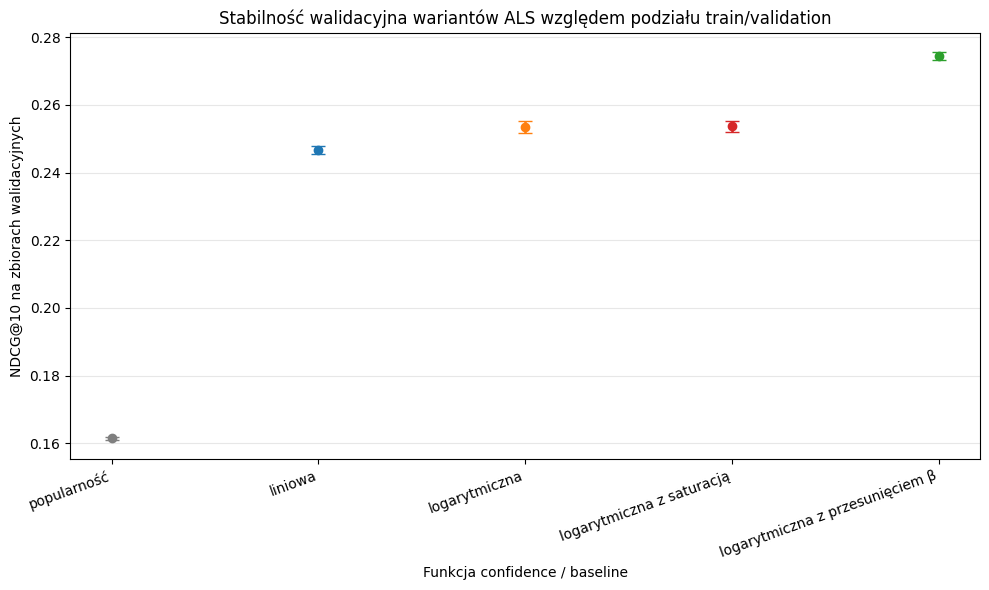

Zapisano: D:\Studiowe\Licencjat\modele\figures\validation\stabilnosc_walidacyjna_ndcg.png


In [8]:
# =========================
# PLOT: VALIDATION NDCG STABILITY
# =========================

plot_df = validation_summary_df.copy()

x = np.arange(len(plot_df))

plt.figure(figsize=(10, 6))

for i, (_, row) in enumerate(plot_df.iterrows()):
    function_name = row["function"]

    plt.errorbar(
        i,
        row[f"ndcg@{K}_mean"],
        yerr=row[f"ndcg@{K}_std"],
        fmt="o",
        capsize=5,
        linewidth=1.8,
        color=function_colors.get(function_name, "black"),
    )

plt.xticks(
    x,
    plot_df["function_label"],
    rotation=20,
    ha="right"
)

plt.ylabel(f"NDCG@{K} na zbiorach walidacyjnych")
plt.xlabel("Funkcja confidence / baseline")
plt.title("Stabilność walidacyjna wariantów ALS względem podziału train/validation")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

path = os.path.join(
    validation_figures_dir,
    "stabilnosc_walidacyjna_ndcg.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")

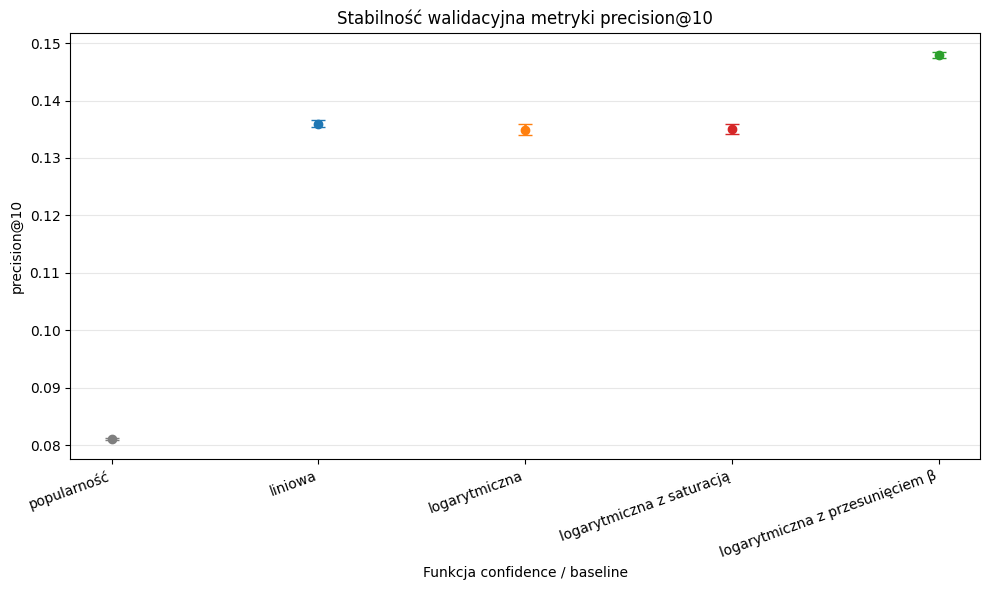

Zapisano: D:\Studiowe\Licencjat\modele\figures\validation\stabilnosc_walidacyjna_precision_10.png


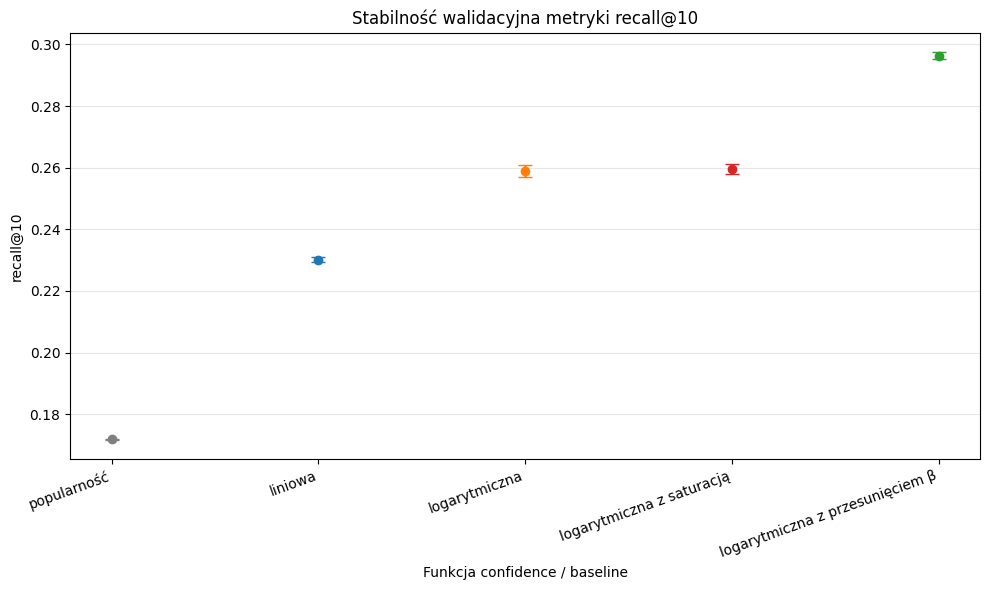

Zapisano: D:\Studiowe\Licencjat\modele\figures\validation\stabilnosc_walidacyjna_recall_10.png


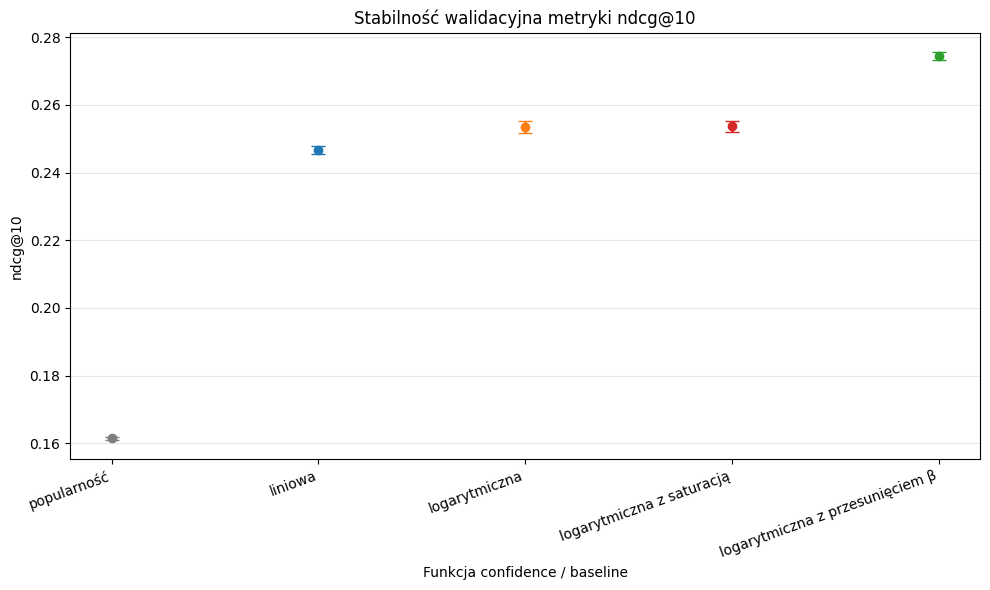

Zapisano: D:\Studiowe\Licencjat\modele\figures\validation\stabilnosc_walidacyjna_ndcg_10.png


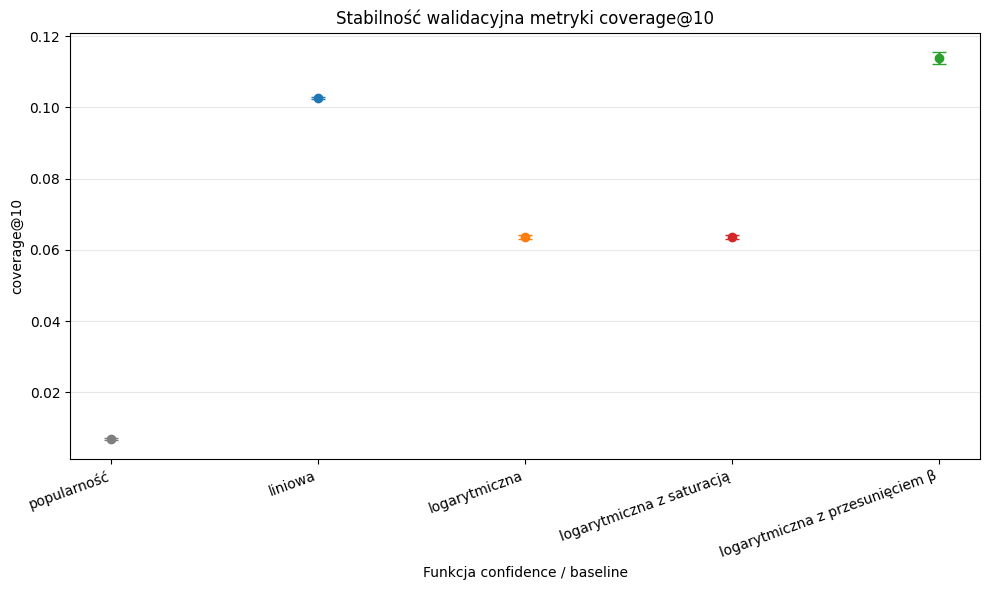

Zapisano: D:\Studiowe\Licencjat\modele\figures\validation\stabilnosc_walidacyjna_coverage_10.png


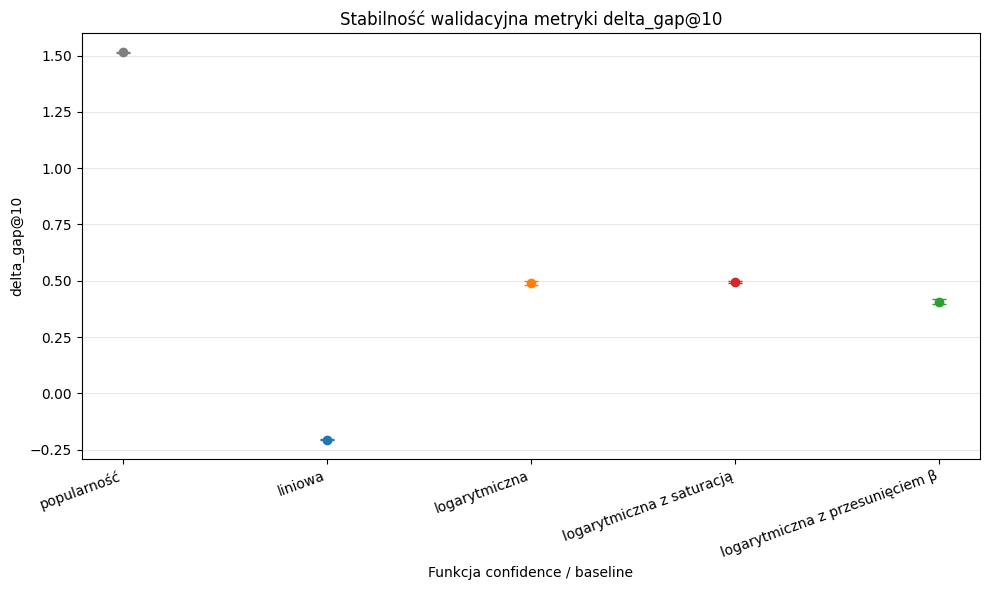

Zapisano: D:\Studiowe\Licencjat\modele\figures\validation\stabilnosc_walidacyjna_delta_gap_10.png


In [9]:
# =========================
# OPTIONAL: PLOTS FOR MAIN METRICS
# =========================

main_metric_cols = [
    f"precision@{K}",
    f"recall@{K}",
    f"ndcg@{K}",
    f"coverage@{K}",
    f"delta_gap@{K}",
]

for metric in main_metric_cols:
    plot_df = validation_summary_df.copy()
    x = np.arange(len(plot_df))

    plt.figure(figsize=(10, 6))

    for i, (_, row) in enumerate(plot_df.iterrows()):
        function_name = row["function"]

        plt.errorbar(
            i,
            row[f"{metric}_mean"],
            yerr=row[f"{metric}_std"],
            fmt="o",
            capsize=5,
            linewidth=1.8,
            color=function_colors.get(function_name, "black"),
        )

    plt.xticks(
        x,
        plot_df["function_label"],
        rotation=20,
        ha="right"
    )

    plt.ylabel(metric)
    plt.xlabel("Funkcja confidence / baseline")
    plt.title(f"Stabilność walidacyjna metryki {metric}")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    safe_metric_name = (
        metric
        .replace("@", "_")
        .replace("/", "_")
    )

    path = os.path.join(
        validation_figures_dir,
        f"stabilnosc_walidacyjna_{safe_metric_name}.png"
    )

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Zapisano: {path}")